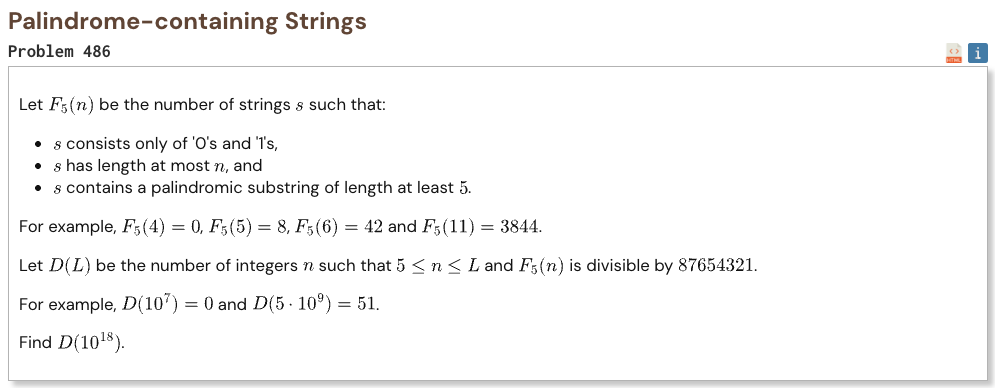

## Initial approach

- count binary strings that avoid palindromes of length 5 and 6
- after a short starting section, the number of valid strings repeats with period 6
- use this pattern to write the cumulative count as a simple linear term plus a power of 2
- reduce the divisibility condition to modular arithmetic
- the power of 64 has a manageable repeating cycle modulo 87654321
- scan one full cycle and use the Chinese remainder theorem to count all matching values up to the huge limit
- add the matches without iterating anywhere near 10 to the power 18

In [1]:
%%time

M = 87_654_321
LIMIT = 10**18
ORDER = 1_216_562

period = M * ORDER

constants = [-114, -82, -50, -18, 16, 52]

inverse_200 = pow(200, -1, M)
inverse_order = pow(ORDER, -1, M)

powers = [
    pow(2, r + 1, M)
    for r in range(6)
]

def count_values(base, low, high):
    if high < low:
        return 0

    if base < low:
        jumps = (low - base + period - 1) // period
        base += jumps * period

    if base > high:
        return 0

    return (high - base) // period + 1

result = 0
power_64 = 1

for phase in range(ORDER):
    for remainder in range(6):
        target = (
            powers[remainder] * power_64
            - constants[remainder]
        ) % M

        q_mod = target * inverse_200 % M

        multiplier = (
            (q_mod - phase) * inverse_order
        ) % M

        base = phase + ORDER * multiplier

        low = max(
            0,
            (12 - remainder + 5) // 6
        )

        high = (
            LIMIT - remainder
        ) // 6

        result += count_values(
            base,
            low,
            high
        )

    power_64 = power_64 * 64 % M

print("Result:", result)

Result: 11408450515
CPU times: user 4.18 s, sys: 36.4 ms, total: 4.22 s
Wall time: 4.3 s
